# **Implementing Decision Tree using Scikit Learn**

In [1]:
# importing required modules
import numpy as np
import pandas as pd

In [2]:
# Loading the PlayTennis dataset
# PlayTennis = pd.read_csv("e:/datafile/PlayTennis.csv")
PlayTennis = pd.read_csv("https://bitbucket.org/toarnabtrainer/aec_ml_mca_feb_2026/raw/47a94fdf99624133359131f51baebcb917ef0a9b/Datafile/PlayTennis.csv")

In [3]:
print (PlayTennis.shape, type(PlayTennis))
PlayTennis

(14, 5) <class 'pandas.core.frame.DataFrame'>


,Outlook,Temperature,Humidity,Wind,Play
0,Sunny,Hot,High,Weak,No
1,Sunny,Hot,High,Strong,No
2,Overcast,Hot,High,Weak,Yes
3,Rain,Mild,High,Weak,Yes
4,Rain,Cool,Normal,Weak,Yes
5,Rain,Cool,Normal,Strong,No
6,Overcast,Cool,Normal,Strong,Yes
7,Sunny,Mild,High,Weak,No
8,Sunny,Cool,Normal,Weak,Yes
9,Rain,Mild,Normal,Weak,Yes


It is easy to implement Decision Tree with numerical values. We can convert all the non numerical values into numerical values using [LabelEncoder](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.LabelEncoder.html)

In [12]:
from sklearn.preprocessing import LabelEncoder
Le = LabelEncoder()

PlayTennis['Outlook'] = Le.fit_transform(PlayTennis['Outlook'])
PlayTennis['Temperature'] = Le.fit_transform(PlayTennis['Temperature'])
PlayTennis['Humidity'] = Le.fit_transform(PlayTennis['Humidity'])
PlayTennis['Wind'] = Le.fit_transform(PlayTennis['Wind'])
PlayTennis['Play'] = Le.fit_transform(PlayTennis['Play'])

In [13]:
print (PlayTennis.shape)
PlayTennis

(14, 5)


,Outlook,Temperature,Humidity,Wind,Play
0,2,1,0,1,0
1,2,1,0,0,0
2,0,1,0,1,1
3,1,2,0,1,1
4,1,0,1,1,1
5,1,0,1,0,0
6,0,0,1,0,1
7,2,2,0,1,0
8,2,0,1,1,1
9,1,2,1,1,1


* Lets split the training data and its coresponding prediction values.
* y - holds all the decisions.
* X - holds the training data.

In [14]:
y = PlayTennis['Play']
X = PlayTennis.drop(['Play'], axis = 1)

In [15]:
print (X.shape, type(X))
X

(14, 4) <class 'pandas.core.frame.DataFrame'>


,Outlook,Temperature,Humidity,Wind
0,2,1,0,1
1,2,1,0,0
2,0,1,0,1
3,1,2,0,1
4,1,0,1,1
5,1,0,1,0
6,0,0,1,0
7,2,2,0,1
8,2,0,1,1
9,1,2,1,1


In [16]:
print (y.shape, type(y))
y

(14,) <class 'pandas.core.series.Series'>


0     0
1     0
2     1
3     1
4     1
5     0
6     1
7     0
8     1
9     1
10    1
11    1
12    1
13    0
Name: Play, dtype: int32

In [17]:
# Fitting the model
from sklearn import tree
clf = tree.DecisionTreeClassifier(criterion = 'entropy')
clf = clf.fit(X, y)

[Text(0.4444444444444444, 0.9, 'x[0] <= 0.5\nentropy = 0.94\nsamples = 14\nvalue = [5, 9]'),
 Text(0.3333333333333333, 0.7, 'entropy = 0.0\nsamples = 4\nvalue = [0, 4]'),
 Text(0.38888888888888884, 0.8, 'True  '),
 Text(0.5555555555555556, 0.7, 'x[2] <= 0.5\nentropy = 1.0\nsamples = 10\nvalue = [5, 5]'),
 Text(0.5, 0.8, '  False'),
 Text(0.3333333333333333, 0.5, 'x[0] <= 1.5\nentropy = 0.722\nsamples = 5\nvalue = [4, 1]'),
 Text(0.2222222222222222, 0.3, 'x[3] <= 0.5\nentropy = 1.0\nsamples = 2\nvalue = [1, 1]'),
 Text(0.1111111111111111, 0.1, 'entropy = 0.0\nsamples = 1\nvalue = [1, 0]'),
 Text(0.3333333333333333, 0.1, 'entropy = 0.0\nsamples = 1\nvalue = [0, 1]'),
 Text(0.4444444444444444, 0.3, 'entropy = 0.0\nsamples = 3\nvalue = [3, 0]'),
 Text(0.7777777777777778, 0.5, 'x[3] <= 0.5\nentropy = 0.722\nsamples = 5\nvalue = [1, 4]'),
 Text(0.6666666666666666, 0.3, 'x[0] <= 1.5\nentropy = 1.0\nsamples = 2\nvalue = [1, 1]'),
 Text(0.5555555555555556, 0.1, 'entropy = 0.0\nsamples = 1\nvalu

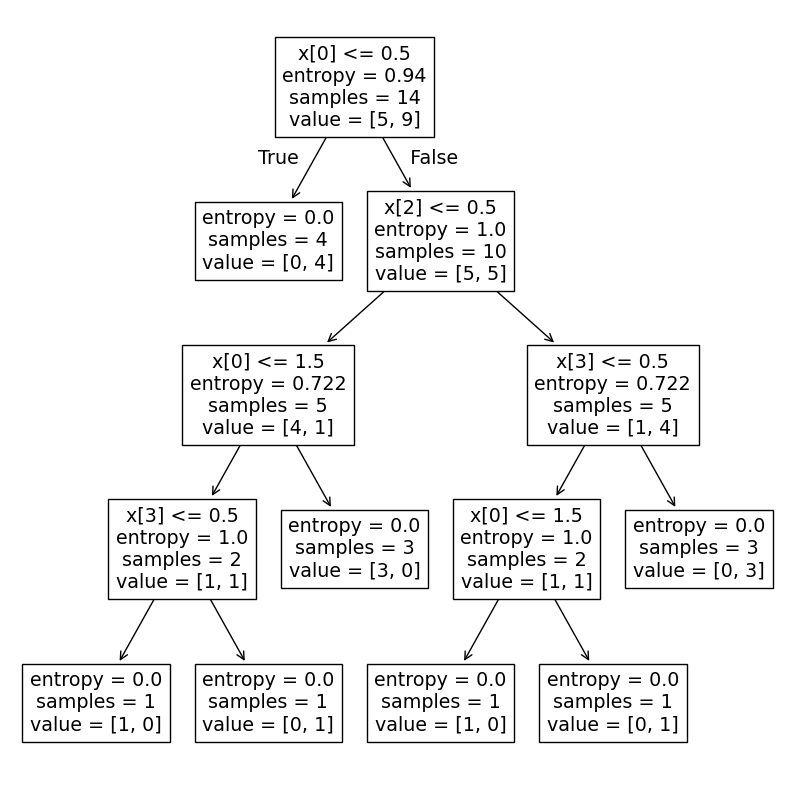

In [18]:
# We can visualize the tree using tree.plot_tree
import matplotlib.pyplot as plt
plt.subplots(figsize=(10, 10))     # for resizing the graph
tree.plot_tree(clf)

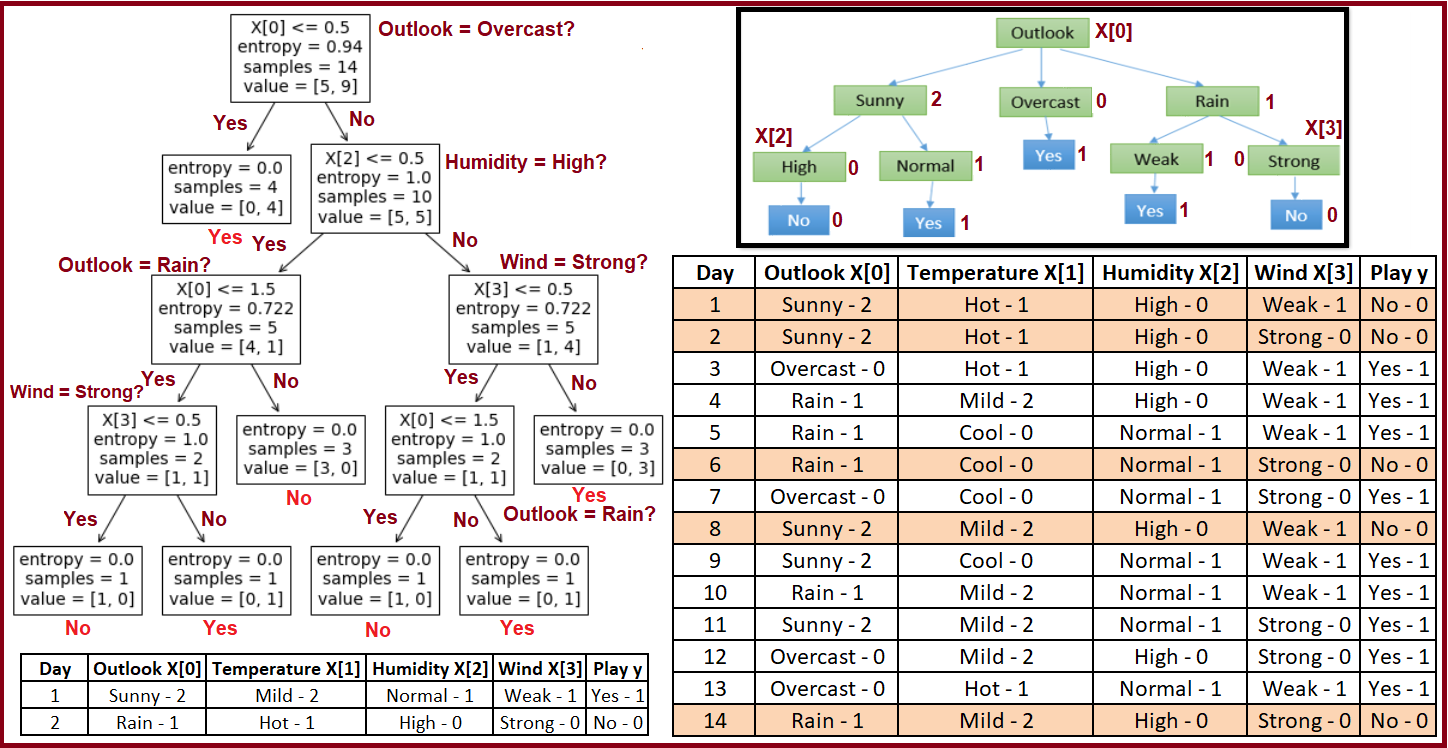

[GraphViz](https://www.graphviz.org/) gives a better and clearer Graph.

In [43]:
# !pip install graphviz
# import graphviz 
# dot_data = tree.export_graphviz(clf, out_file = None) 
# graph = graphviz.Source(dot_data) 
# graph

In the above graph,

* X[0] -> Outlook
* X[1] -> Temperature
* X[2] -> Humidity
* X[3] -> Wind

values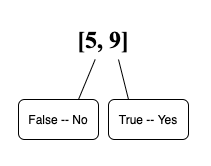



We can just make the model to predict our train data.

In [44]:
# The predictions are stored in X_pred
X_pred = clf.predict(X)

In [45]:
# verifying if the model has predicted it all right.
X_pred == y

0     True
1     True
2     True
3     True
4     True
5     True
6     True
7     True
8     True
9     True
10    True
11    True
12    True
13    True
Name: Play, dtype: bool

**Test Data -**<br>
<table border = 4 align = left>
    <tr><th>Rows</th><th>Outlook</th><th>Temperature</th><th>Humidity</th><th>Wind</th><th>Play</th></tr>
    <tr><th>1</th><td>Sunny</td><td>Mild</td><td>Normal</td><td>Weak</td><td>Yes</td></tr>
    <tr><th>2</th><td>Rain</td><td>Hot</td><td>High</td><td>Strong</td><td>No</td></tr>
</table>

In [47]:
X_input = [[2, 2, 1, 1] , [1, 1, 0, 0]]
df_columns = ["Outlook", "Temperature", "Humidity", "Wind"]
X_input_df = pd.DataFrame(data = X_input, columns = df_columns)
X_input_df

,Outlook,Temperature,Humidity,Wind
0,2,2,1,1
1,1,1,0,0


In [51]:
X_pred = clf.predict(X_input_df)
print (X_pred, type(X_pred))

[1 0] <class 'numpy.ndarray'>
